# hBN bilayer: results

Reference results of the first benchmark of the project (`docs/04_benchmark_systems.md`): bilayer hBN computed
explicitly (AA' and AB stackings) vs the monolayer, which will later be combined with the second layer treated as
an effective substrate (Notes, Sec. 2). This notebook collects the physical results only; the calculations, the
convergence studies and the checks are in `DFT_Analysis.ipynb` and `GW_Analysis.ipynb`.

Rule: this notebook reads **only** the JSON files in `results/` (tracked in git), written by the export sections of
the computational notebooks. It needs only numpy and matplotlib and runs on any machine with the repository. The same
files are the data to share and to use for the figures of the notes.

| file | content | written by |
|---|---|---|
| `results/dft_ground_state.json` | parameters, geometry, total energies and gaps (PBE) | DFT_Analysis.ipynb |
| `results/dft_bands.json` | KS bands on $\Gamma$-M-K-$\Gamma$ | DFT_Analysis.ipynb |
| `results/dft_layer_character.json` | layer weights of the bilayer states at $\Gamma$ and K | DFT_Analysis.ipynb |

In [1]:
import json, os
import numpy as np
import matplotlib.pyplot as plt

res_dir = 'results'
def load(name):
    with open(os.path.join(res_dir, name + '.json')) as f: return json.load(f)

gs, dft_bands, lay = load('dft_ground_state'), load('dft_bands'), load('dft_layer_character')
labels = {'ML_bot': 'ML', 'ML_top_AA1': 'ML top (AA\')', 'ML_top_AB': 'ML top (AB)', 'AA1': "AA'", 'AB': 'AB'}
tex_k = {'Gamma': r'$\Gamma$', 'M': 'M', 'K': 'K'}

## Systems and computational setup
- Monolayer hBN (ML) and the two bilayers AA' (stacking of bulk hBN, B over N and N over B, D3d, equivalent layers)
  and AB (top B over bottom N, top N over a hexagon centre, C3v, inequivalent layers with a small out-of-plane dipole).
- Same lattice constant (experimental bulk value), interlayer distance, cell height, cutoff and k grids for all the
  systems: explicit and effective calculations differ only by the method.
- The monolayer is computed in the exact position of each layer of each bilayer (`ML_bot`, `ML_top_AA1`,
  `ML_top_AB`): identical energies and bands, used later to build the response of layer and substrate.
- The interlayer distance is fixed (d = 3.33 Å, as in Guo et al., PRB 102, 205113 (2020)); PBE does not bind the
  layers (a PBE+D3 check gives 3.44 Å for both stackings, DFT_Analysis.ipynb).

In [2]:
p = gs['parameters']
print('%s, %s, spin-orbit: %s' % (p['functional'], p['pseudopotentials']['family'], p['spin_orbit']))
print('ecutwfc = %s Ry, scf k grid %s, a = %.3f A, c = %.2f A (%.1f bohr), d = %.2f A'
      % (p['ecutwfc_Ry'], 'x'.join(map(str, p['k_grid'])), p['a'], p['c'], p['c_bohr'], p['d_interlayer']))
print()
for s, v in gs['systems'].items():
    print('%-10s %s' % (s, v['description']))
    for at in v['atoms']: print('%14s %s  (%8.4f %8.4f %8.4f) A' % ('', at['species'], *at['position']))

PBE, SG15 ONCV v1.2, scalar relativistic, no NLCC, spin-orbit: False
ecutwfc = 80 Ry, scf k grid 12x12x1, a = 2.504 A, c = 21.17 A (40.0 bohr), d = 3.33 A

ML_bot     monolayer = bottom layer of the bilayers (z = -d/2); layer and substrate of the effective scheme
               B  (  0.0000   1.4457  -1.6650) A
               N  (  1.2520   0.7228  -1.6650) A
ML_top_AA1 monolayer = top layer of the AA' bilayer, alone (z = +d/2)
               N  (  0.0000   1.4457   1.6650) A
               B  (  1.2520   0.7228   1.6650) A
ML_top_AB  monolayer = top layer of the AB bilayer, alone (z = +d/2)
               B  (  1.2520   0.7228   1.6650) A
               N  (  0.0000   0.0000   1.6650) A
AA1        bilayer, AA' stacking (bulk hBN; B over N, N over B), D3d
               B  (  0.0000   1.4457  -1.6650) A
               N  (  1.2520   0.7228  -1.6650) A
               N  (  0.0000   1.4457   1.6650) A
               B  (  1.2520   0.7228   1.6650) A
AB         bilayer, AB stacking (top B

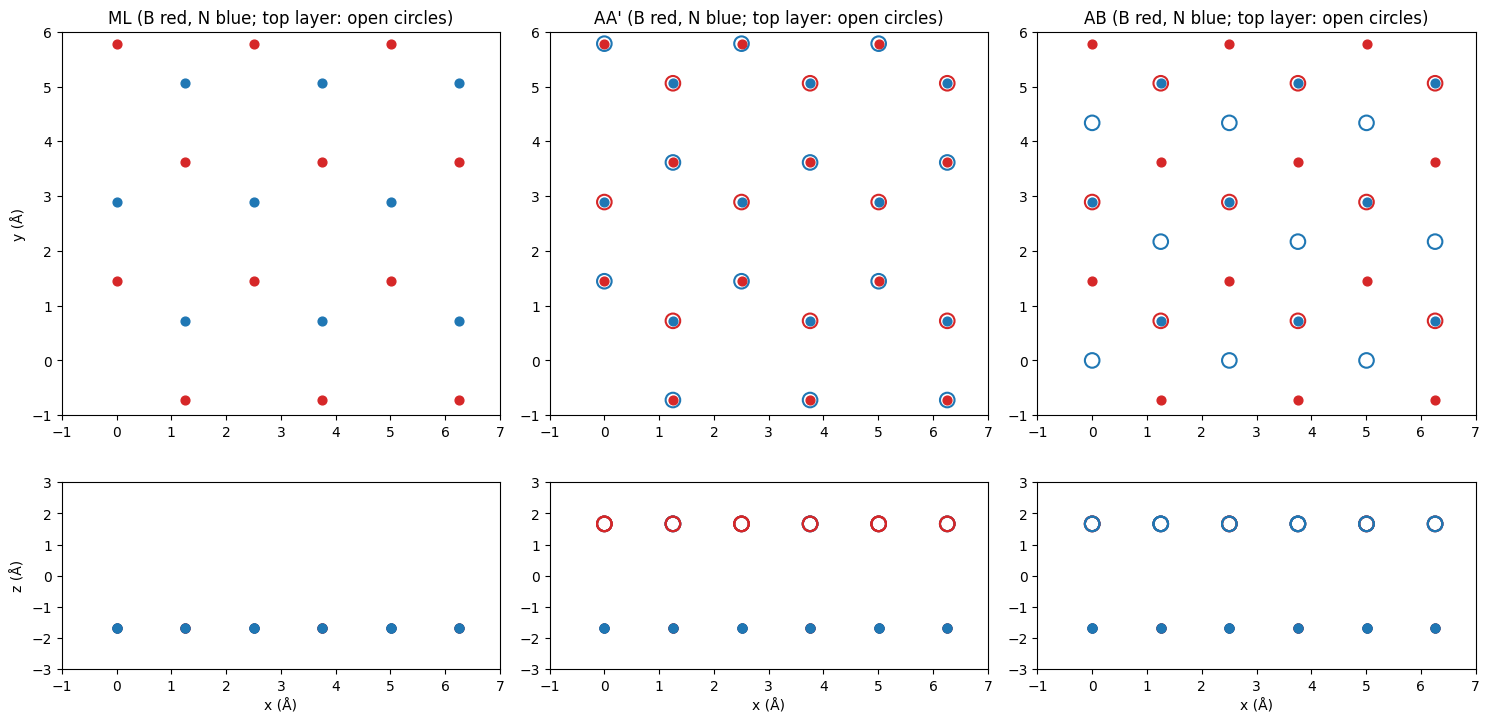

In [3]:
# Top view (xy, a few cells) and side view (xz) of the monolayer and of the bilayers
a1, a2 = np.array(gs['lattice_vectors'][0]), np.array(gs['lattice_vectors'][1])
col = {'B': 'tab:red', 'N': 'tab:blue'}
fig, ax = plt.subplots(nrows=2, ncols=3, figsize=(15, 8), gridspec_kw={'height_ratios': [3, 1]})
for i, s in enumerate(['ML_bot', 'AA1', 'AB']):
    for at in gs['systems'][s]['atoms']:
        top = at['position'][2] > 0
        for n1 in range(-1, 4):
            for n2 in range(-1, 4):
                r = np.array(at['position']) + n1 * a1 + n2 * a2
                kw = dict(s=110, facecolors='none', edgecolors=col[at['species']], linewidths=1.5) if top else \
                     dict(s=40, color=col[at['species']])
                ax[0, i].scatter(r[0], r[1], **kw)
                ax[1, i].scatter(r[0], r[2], **kw)
    ax[0, i].set_title(labels[s] + ' (B red, N blue; top layer: open circles)')
    ax[0, i].set_aspect('equal'); ax[0, i].set_xlim(-1, 7); ax[0, i].set_ylim(-1, 6)
    ax[1, i].set_ylim(-3, 3); ax[1, i].set_xlim(-1, 7); ax[1, i].set_xlabel('x (Å)')
ax[0, 0].set_ylabel('y (Å)'); ax[1, 0].set_ylabel('z (Å)')
plt.tight_layout()

## DFT (PBE) ground state
Total energies and gaps on the k grid of the scf (12x12x1, which contains $\Gamma$, M and K).

In [4]:
print('%-11s %16s %12s %16s %14s' % ('system', 'E_tot (Ha)', 'gap (eV)', 'direct gap (eV)', 'gap at G (eV)'))
for s, v in gs['systems'].items():
    print('%-11s %16.6f %12.4f %16.4f %14.4f' % (s, v['total_energy_Ha'], v['gap'], v['direct_gap'], v['gap_Gamma']))

system            E_tot (Ha)     gap (eV)  direct gap (eV)  gap at G (eV)
ML_bot            -12.880929       4.7146           4.7146         6.0871
ML_top_AA1        -12.880929       4.7145           4.7145         6.0871
ML_top_AB         -12.880929       4.7144           4.7144         6.0870
AA1               -25.761078       4.5412           4.7649         6.1911
AB                -25.761102       4.5355           4.5851         6.1464


- The three monolayers coincide (within 0.2 meV): same crystal, moved or rotated in the cell.
- Monolayer: direct gap at K, 4.715 eV; the lowest conduction state at $\Gamma$ (nearly-free-electron, NFE, state)
  is almost degenerate with the one at K (within 1 meV).
- Bilayers: indirect gap K $\to$ M, 0.17-0.18 eV below the monolayer gap. The two stackings are degenerate in PBE
  (AB lower by 0.65 meV per cell).

## DFT (PBE) band structures

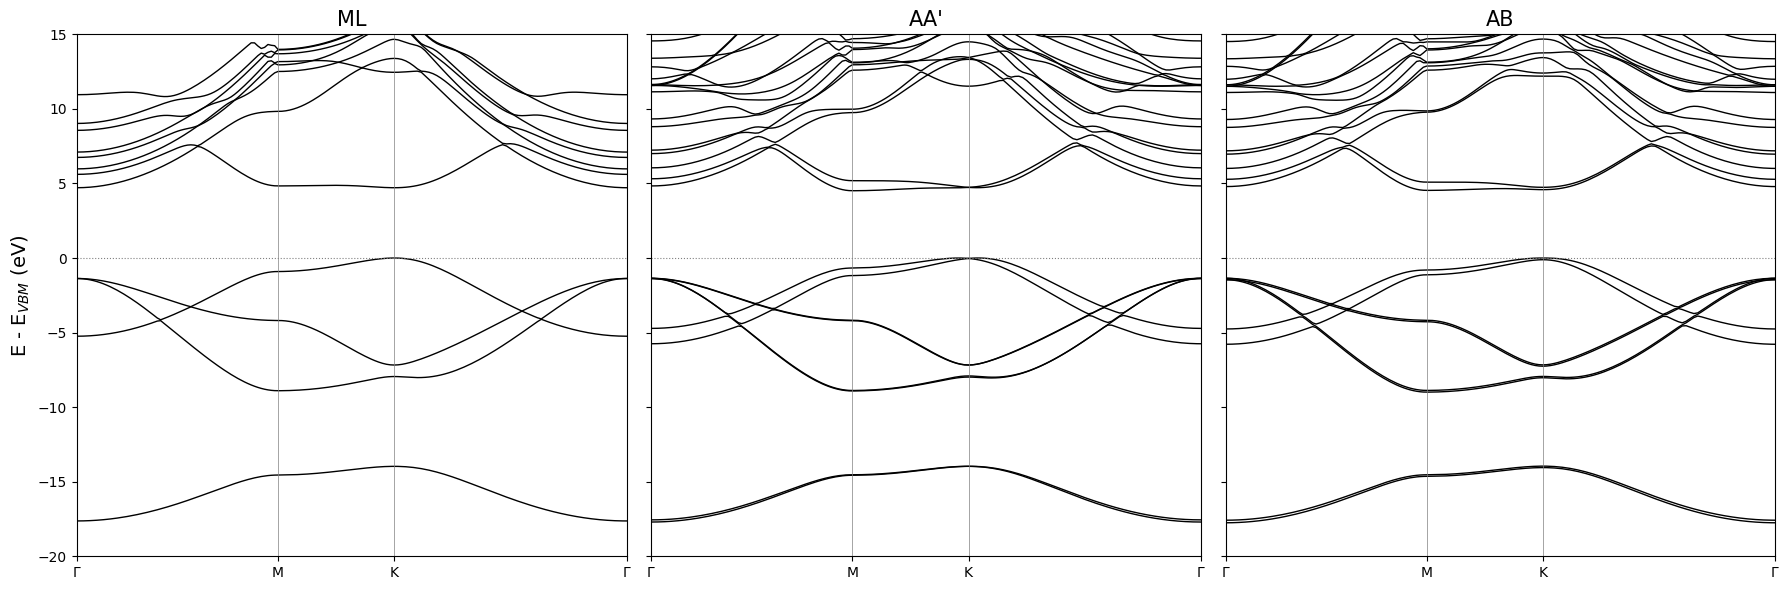

In [5]:
def plot_bands(ax, d, system, **kw):
    v = d['systems'][system]
    k, E = np.array(v['kpath']), np.array(v['bands'])
    for i, e in enumerate(E): ax.plot(k, e, label=kw.pop('label', None) if i == 0 else None, **kw)
    pos = v['high_symmetry_positions']
    for x in pos: ax.axvline(x, color='gray', lw=0.5)
    ax.set_xticks(pos); ax.set_xticklabels([tex_k[l] for l in d['path']['labels']]); ax.set_xlim(pos[0], pos[-1])

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(18, 6), sharey=True)
for a, s in zip(ax, ['ML_bot', 'AA1', 'AB']):
    plot_bands(a, dft_bands, s, color='k', lw=1)
    a.axhline(0, color='gray', ls=':', lw=0.8); a.set_title(labels[s], size=15)
ax[0].set_ylabel('E - E$_{VBM}$ (eV)', size=14); ax[0].set_ylim(-20, 15)
plt.tight_layout()

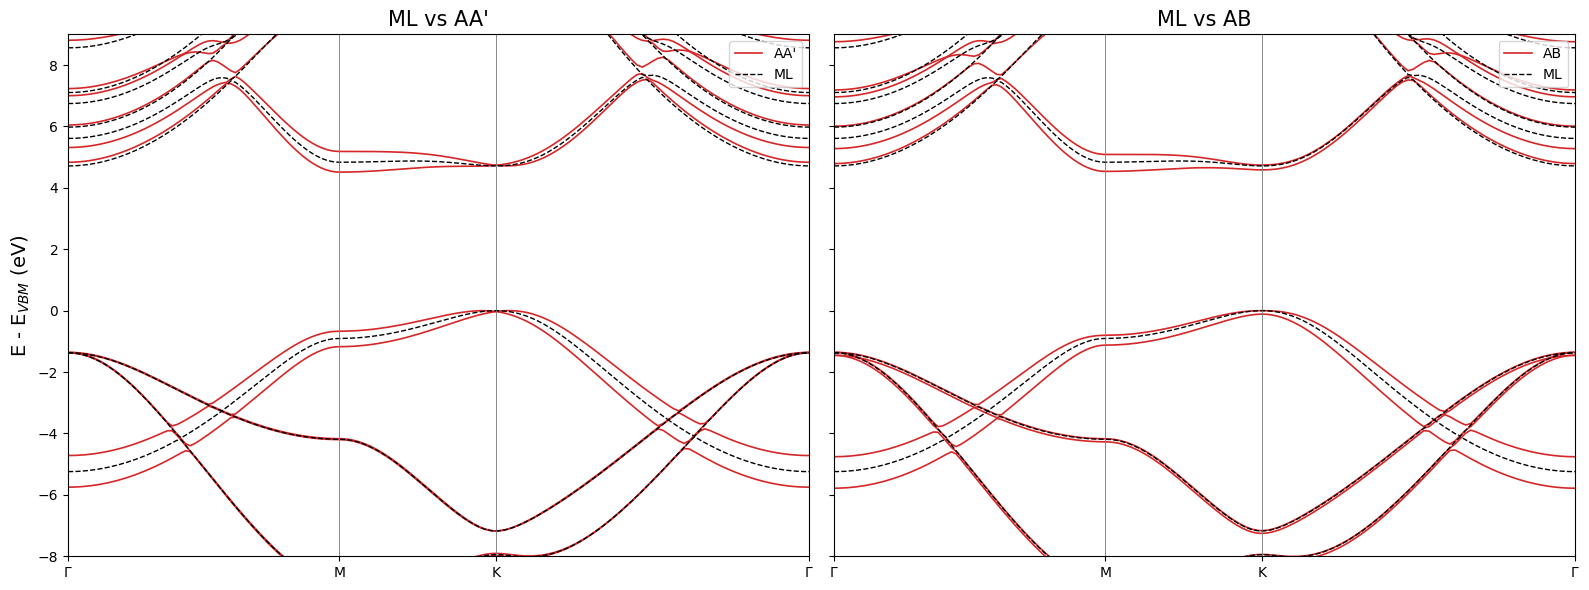

In [6]:
# Monolayer vs bilayers, window around the gap (each system from its own VBM)
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 6), sharey=True)
for a, s in zip(ax, ['AA1', 'AB']):
    plot_bands(a, dft_bands, s, color='tab:red', lw=1.2, label=labels[s])
    plot_bands(a, dft_bands, 'ML_bot', color='k', lw=1, ls='--', label='ML')
    a.set_ylim(-8, 9); a.set_title('ML vs %s' % labels[s], size=15); a.legend(loc='upper right')
ax[0].set_ylabel('E - E$_{VBM}$ (eV)', size=14)
plt.tight_layout()

In [7]:
# Band edges at the high-symmetry points (eV, from the VBM on the path)
def at_point(system, label):
    v = dft_bands['systems'][system]
    ik = int(np.argmin(abs(np.array(v['kpath']) - v['high_symmetry_positions'][dft_bands['path']['labels'].index(label)])))
    E, nv = np.array(v['bands'])[:, ik], v['n_occupied_bands']
    nl = nv // 4                                   # number of layers: top valence / lowest conduction pair
    return E[nv - nl:nv], E[nv:nv + nl]
print('%-8s %-6s %-22s %-22s' % ('system', 'k', 'top valence', 'lowest conduction'))
for s in ['ML_bot', 'AA1', 'AB']:
    for l in ['Gamma', 'M', 'K']:
        v, c = at_point(s, l)
        print('%-8s %-6s %-22s %-22s' % (labels[s], l, ', '.join('%.3f' % x for x in v), ', '.join('%.3f' % x for x in c)))
for s in ['AA1', 'AB']:
    v = dft_bands['systems'][s]; E = np.array(v['bands']); nv = v['n_occupied_bands']
    iv, ic = E[nv - 1].argmax(), E[nv].argmin()
    print('%s: VBM at path coordinate %.4f (K at %.4f), CBM at %.4f (M at %.4f); gap on the path %.4f eV'
          % (labels[s], v['kpath'][iv], v['high_symmetry_positions'][2], v['kpath'][ic], v['high_symmetry_positions'][1],
             E[nv].min() - E[nv - 1].max()))

system   k      top valence            lowest conduction     
ML       Gamma  -1.372                 4.714                 
ML       M      -0.905                 4.834                 
ML       K      0.000                  4.714                 
AA'      Gamma  -1.358, -1.358         4.833, 5.314          
AA'      M      -1.173, -0.670         4.513, 5.185          
AA'      K      -0.029, -0.029         4.736, 4.736          
AB       Gamma  -1.355, -1.355         4.791, 5.278          
AB       M      -1.123, -0.803         4.535, 5.088          
AB       K      -0.113, 0.000          4.585, 4.741          
AA': VBM at path coordinate 0.9440 (K at 0.9107), CBM at 0.5774 (M at 0.5774); gap on the path 4.5125 eV
AB: VBM at path coordinate 0.9107 (K at 0.9107), CBM at 0.5774 (M at 0.5774); gap on the path 4.5352 eV


- **At K** the AA' states stay pairwise degenerate (equivalent layers, weak coupling of the K states): the direct gap
  at K changes by only +22 meV with respect to the monolayer. In AB the two layers are inequivalent and the K states
  split by 0.11 eV (valence) and 0.16 eV (conduction).
- **At M and $\Gamma$** the $\pi$/$\pi^*$ states and the NFE states of the two layers hybridize strongly
  (bonding/antibonding splittings of 0.5-0.67 eV): the bilayer CBM moves to M and the gap becomes indirect,
  K $\to$ M, 0.17 eV below the monolayer gap. This is a ground-state hybridization effect, not a screening effect.
- In AA' the VBM is slightly off K, towards $\Gamma$ (29 meV above the value at K): the gaps on the path are
  smaller than those on the k grids, which contain K but not this point.
- Consequence for the benchmark: the assumption of no overlap between the states of the two layers (Notes, Sec. 2.1)
  holds at K and fails for the conduction states at M and $\Gamma$. The effective scheme keeps the KS states of the
  free-standing layer, so it cannot reproduce the DFT differences above: the explicit vs effective comparison is
  made on the quasiparticle corrections (QP - KS) at K.

### Layer character of the bilayer states at $\Gamma$ and K
Fraction of $|\psi_{nk}|^2$ in the bottom layer (bands 7-8 valence, 9-10 conduction).

In [8]:
print('%-6s %-6s ' % ('system', 'k') + ''.join('%8s' % ('b' + b) for b in ['7', '8', '9', '10']))
for s, v in lay['systems'].items():
    for k, w in v.items():
        print('%-6s %-6s ' % (labels[s], k) + ''.join('%8.3f' % w[b] for b in ['7', '8', '9', '10']))

system k            b7      b8      b9     b10
AA'    Gamma     0.500   0.500   0.499   0.500
AA'    K         0.499   0.500   0.499   0.500
AB     Gamma     0.003   0.003   0.565   0.437
AB     K         0.989   0.006   0.977   0.021


- AA': degenerate pairs, 50/50 on the two layers (equivalent layers); any combination of a pair, also the
  layer-localized one, has the same GW correction.
- AB at K: states localized on one layer (98-99%): b7 (valence) and b9 (conduction) on the bottom layer, b8 and b10
  on the top layer. The KS gap b9 - b8 at K is an **interlayer** gap; the gaps of the single layers at K are
  b9 - b7 (bottom) and b10 - b8 (top). At $\Gamma$ the top valence pair is on the top layer, the NFE conduction
  states are spread over both layers.

## GW (G0W0, PPA) quasiparticle band structures
To be added when the full-IBZ QP runs of ML, AA' and AB are complete (GW_Analysis.ipynb, export to
`results/gw_*.json`).